<a href="https://colab.research.google.com/github/AnnisB/AnnisB/blob/main/TP2_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 Regression

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

import pandas as pd

## Data visualization and pre-processing

In [ ]:
data = np.load("ECoG.npz")

print("Available variables :", data.files)

Available variables : ['Yall', 'Fe', 'Xall']


In [ ]:
Xall = data["Xall"]
Yall = data["Yall"]
Fe = data["Fe"]

print("Xall :", Xall.shape)
print("Yall :", Yall.shape)
print("Fe :", Fe)

Xall : (3327, 64)
Yall : (3327, 1)
Fe : [[50]]


In [ ]:
Yall = Yall.ravel()
Fe = Fe.item()

print(Yall.shape)
print(Fe)

(3327,)
50


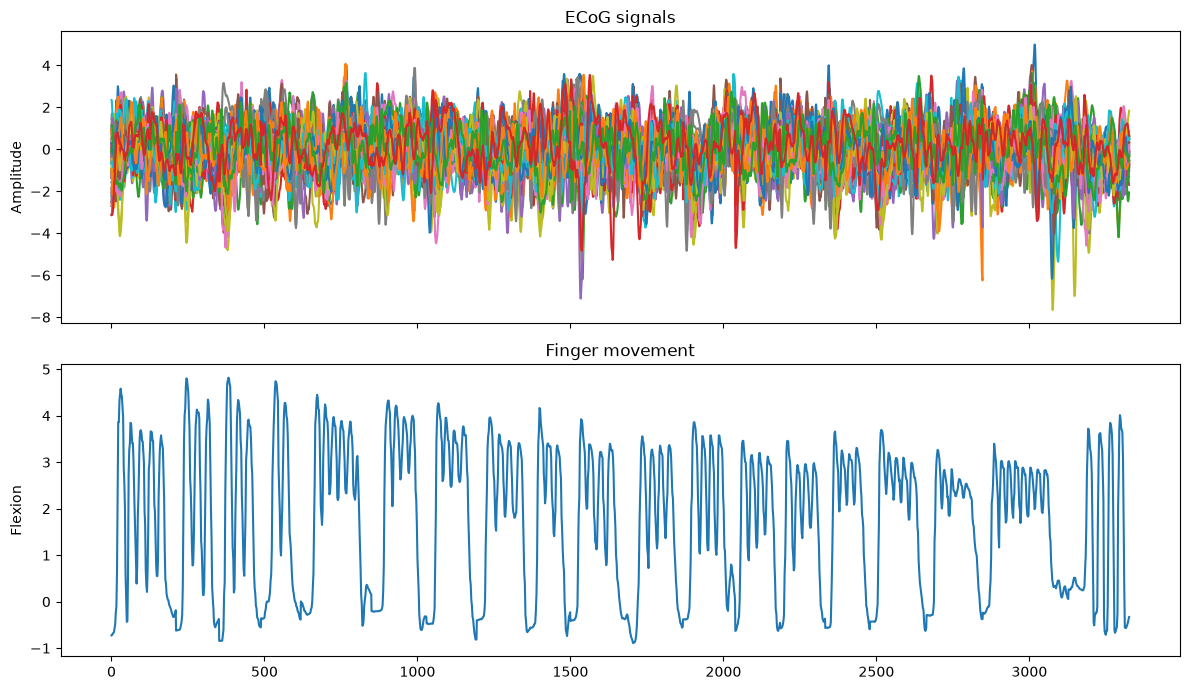

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(Xall)
axes[0].set_title("ECoG signals")
axes[0].set_ylabel("Amplitude")

axes[1].plot(Yall)
axes[1].set_title("Finger movement")
axes[1].set_ylabel("Flexion")

plt.tight_layout()
plt.show()

The ECoG signals are quite noisy and fluctuate around zero, while the finger movement shows clear and repeated changes in flexion.

There is no obvious relationship between the two signals from this plot alone.

Combining information from multiple electrodes may help predict finger movement.

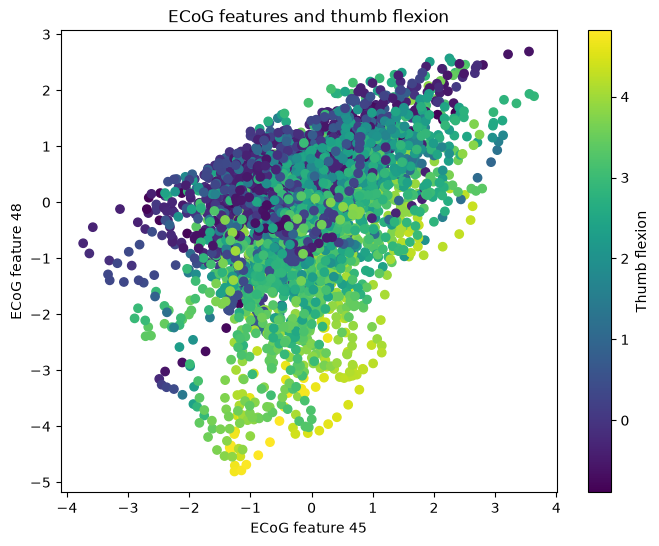

In [ ]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(Xall[:, 45], Xall[:, 48], c=Yall)

plt.xlabel("ECoG feature 45")
plt.ylabel("ECoG feature 48")
plt.title("ECoG features and thumb flexion")
plt.colorbar(scatter, label="Thumb flexion")
plt.show()

The two ECoG features appear to be positively correlated.

We can also see a relationship with thumb flexion, as higher flexion values tend to appear in the lower part of the plot.

However, the colors overlap quite a lot, so these two features alone may not be enough for accurate predictions.

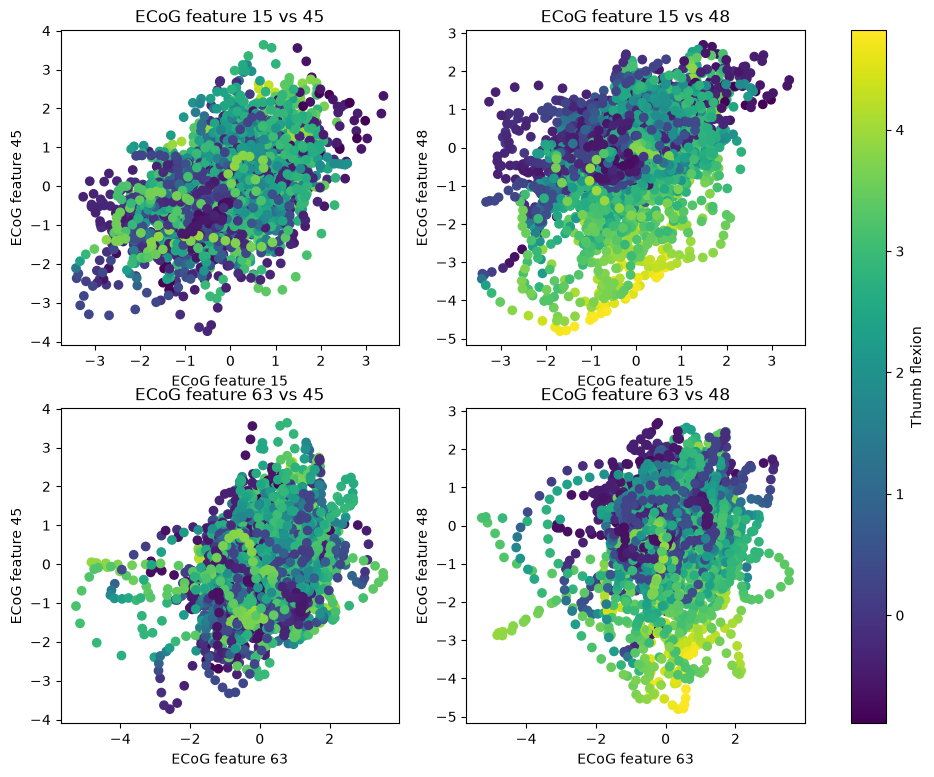

In [ ]:
pairs = [(15, 45), (15, 48), (63, 45), (63, 48)]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (i, j) in zip(axes.flat, pairs):
    scatter = ax.scatter(Xall[:, i], Xall[:, j], c=Yall)

    ax.set_xlabel(f"ECoG feature {i}")
    ax.set_ylabel(f"ECoG feature {j}")
    ax.set_title(f"ECoG feature {i} vs {j}")

fig.colorbar(scatter, ax=axes.ravel().tolist(), label="Thumb flexion",)

plt.show()

In [ ]:
n = 1000
X_train = Xall[:n, :]
X_test = Xall[n:, :]

y_train = Yall[:n]
y_test = Yall[n:]

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (1000, 64) (1000,)
Testing: (2327, 64) (2327,)


## Least Squares regression (LS)

In [ ]:
X_aug = np.concatenate([X_train, np.ones((X_train.shape[0], 1))], axis = 1)

In [ ]:
A = X_aug.T @ X_aug
B = X_aug.T @ y_train

theta = np.linalg.solve(A, B)
w = theta[:-1]
b = theta[-1]

print("Augmented matrix:", X_aug.shape)
print("Weights:", w.shape)
print("Bias:", b)

Augmented matrix: (1000, 65)
Weights: (64,)
Bias: 1.9008125499844706


In [ ]:
y_pred_train = X_train @ w + b
y_pred_test = X_test @ w + b

print("Training predictions:", y_pred_train.shape)
print("Test predictions:", y_pred_test.shape)

Training predictions: (1000,)
Test predictions: (2327,)


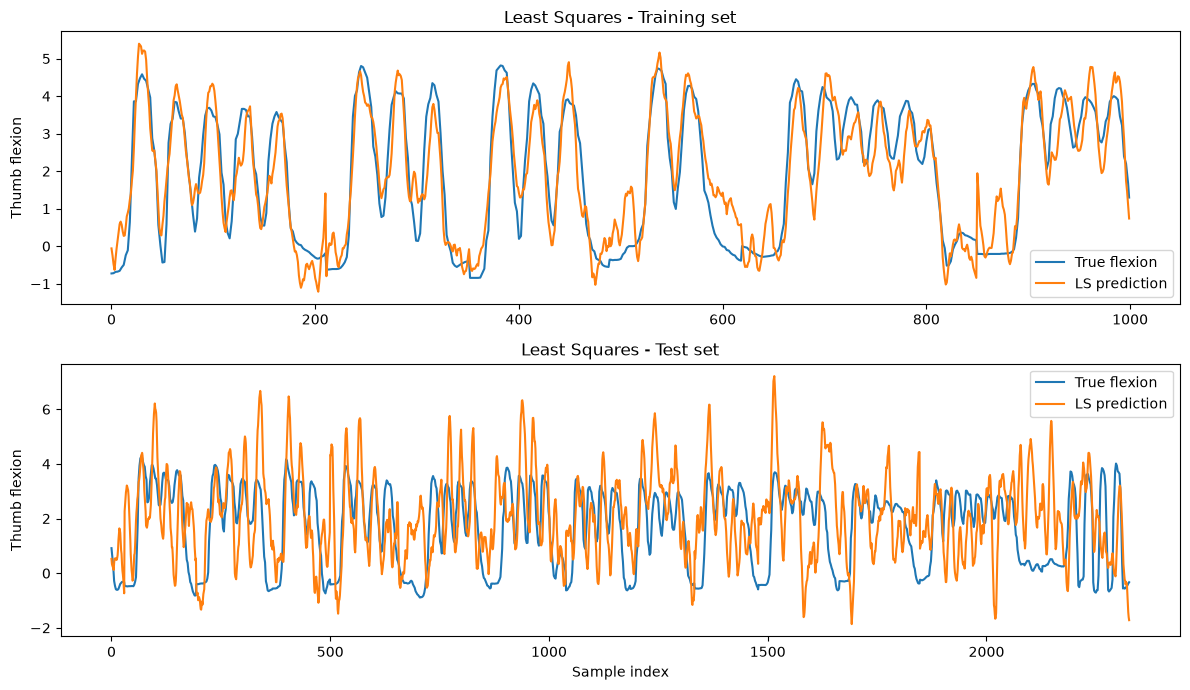

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(y_train, label="True flexion")
axes[0].plot(y_pred_train, label="LS prediction")
axes[0].set_title("Least Squares - Training set")
axes[0].set_ylabel("Thumb flexion")
axes[0].legend()

axes[1].plot(y_test, label="True flexion")
axes[1].plot(y_pred_test, label="LS prediction")
axes[1].set_title("Least Squares - Test set")
axes[1].set_xlabel("Sample index")
axes[1].set_ylabel("Thumb flexion")
axes[1].legend()

plt.tight_layout()
plt.show()

The Least Squares model fits the training data quite well and follows most of the finger movements.

However, the predictions on the test set are much less accurate, with larger fluctuations and several incorrect peaks.

This suggests that the model does not generalize very well to unseen data.

In [ ]:
mse_train = mean_squared_error(y_train, y_pred_train)
mse_test = mean_squared_error(y_test, y_pred_test)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print(f"Training - MSE: {mse_train:.4f}, R2: {r2_train:.4f}")
print(f"Test     - MSE: {mse_test:.4f}, R2: {r2_test:.4f}")

Training - MSE: 0.5041, R2: 0.8395
Test     - MSE: 3.0455, R2: -0.4282


The LS model performs well on the training set, with an R² of 0.84 and a low MSE.

However, the test R² is negative and the MSE is much higher.

This confirms that the model struggles to generalize to unseen data, suggesting possible overfitting.

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Weights match:", np.allclose(w, model.coef_))
print("Bias matches:", np.allclose(b, model.intercept_))

print("Maximum weight difference:", np.max(np.abs(w - model.coef_)))
print("Bias difference:", abs(b - model.intercept_))

Weights match: True
Bias matches: True
Maximum weight difference: 3.5166314305001833e-14
Bias difference: 4.218847493575595e-15


Our implementation gives the same weights and bias as Scikit-learn, with only very small numerical differences.

This confirms that our Least Squares solution is correct.

# Ridge Regression

In [ ]:
ridge = Ridge()
ridge.fit(X_train, y_train)

y_ridge_train = ridge.predict(X_train)
y_ridge_test = ridge.predict(X_test)

print("Ridge - alpha = 1")
print(f"Training MSE: {mean_squared_error(y_train, y_ridge_train):.4f}")
print(f"Training R2:  {r2_score(y_train, y_ridge_train):.4f}")
print(f"Test MSE:     {mean_squared_error(y_test, y_ridge_test):.4f}")
print(f"Test R2:      {r2_score(y_test, y_ridge_test):.4f}")

print(f"\nLS weight norm:    {np.linalg.norm(w):.4f}")
print(f"Ridge weight norm: {np.linalg.norm(ridge.coef_):.4f}")

Ridge - alpha = 1
Training MSE: 0.5042
Training R2:  0.8395
Test MSE:     3.0038
Test R2:      -0.4086

LS weight norm:    2.6313
Ridge weight norm: 2.5880


Ridge with alpha = 1 gives slightly better test results than Least Squares, but the improvement is small.

The weight norm is also lower, showing the effect of L2 regularization.

A stronger regularization might improve generalization further.

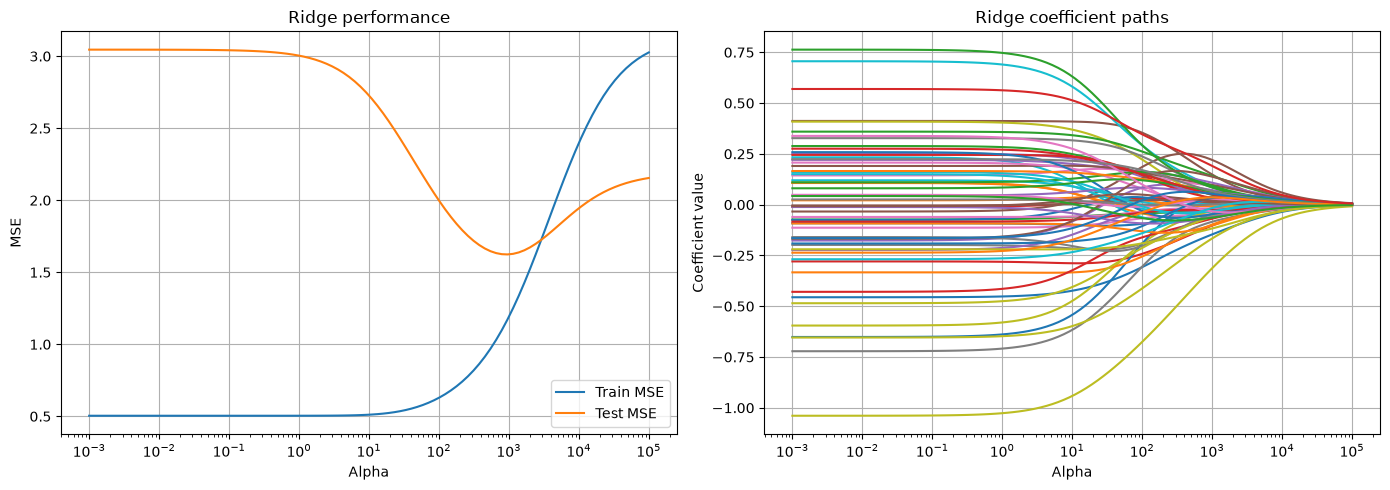

In [ ]:
alphas = np.logspace(-3, 5, 100)

mse_train_values = []
mse_test_values = []
weights = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    mse_train_values.append(mean_squared_error(y_train, pred_train))
    mse_test_values.append(mean_squared_error(y_test, pred_test))

    weights.append(model.coef_)

weights = np.array(weights)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogx(alphas, mse_train_values, label="Train MSE")
axes[0].semilogx(alphas, mse_test_values, label="Test MSE")
axes[0].set_xlabel("Alpha")
axes[0].set_ylabel("MSE")
axes[0].set_title("Ridge performance")
axes[0].legend()
axes[0].grid(True)

axes[1].semilogx(alphas, weights)
axes[1].set_xlabel("Alpha")
axes[1].set_ylabel("Coefficient value")
axes[1].set_title("Ridge coefficient paths")
axes[1].grid(True)

plt.tight_layout()
plt.show()

As alpha increases, the training MSE increases while the test MSE first decreases and then increases again.

This shows how regularization helps reduce overfitting, but too much regularization leads to underfitting.

We can also see that the coefficients gradually shrink towards zero as alpha increases.

In [ ]:
best_idx = np.argmin(mse_test_values)
best_alpha = alphas[best_idx]

ridge_best = Ridge(alpha=best_alpha)
ridge_best.fit(X_train, y_train)

y_ridge_train = ridge_best.predict(X_train)
y_ridge_test = ridge_best.predict(X_test)

print(f"Best alpha: {best_alpha:.4f}")
print(f"Training MSE: {mean_squared_error(y_train, y_ridge_train):.4f}")
print(f"Test MSE: {mean_squared_error(y_test, y_ridge_test):.4f}")
print(f"Training R2: {r2_score(y_train, y_ridge_train):.4f}")
print(f"Test R2: {r2_score(y_test, y_ridge_test):.4f}")

Best alpha: 954.5485
Training MSE: 1.1719
Test MSE: 1.6239
Training R2: 0.6268
Test R2: 0.2385


The best Ridge model uses an alpha of about 955.

Compared to Least Squares, the training performance decreases, but the test MSE is reduced by almost 47% and the test R² becomes positive.

This shows that regularization significantly improves generalization, although the predictions are still not very accurate.

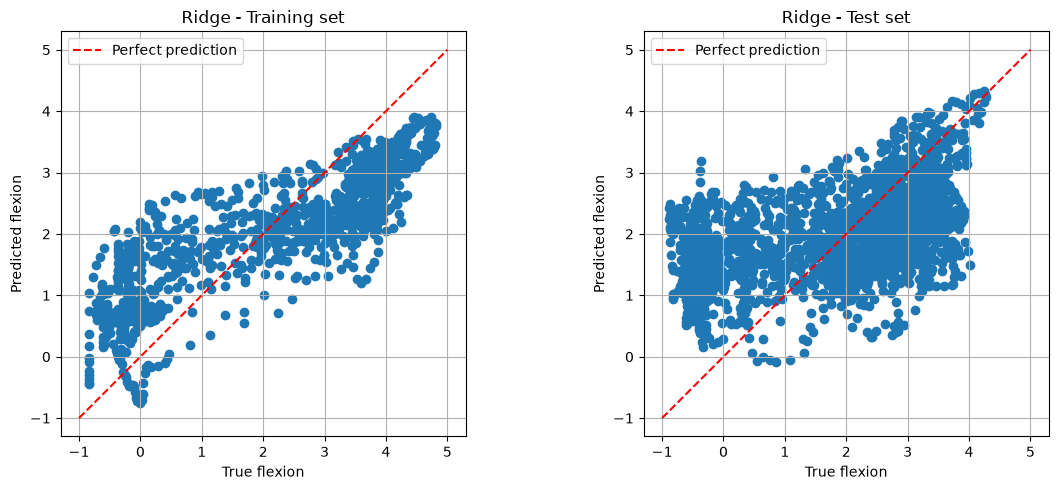

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_train, y_ridge_train)
axes[0].set_title("Ridge - Training set")

axes[1].scatter(y_test, y_ridge_test)
axes[1].set_title("Ridge - Test set")

for ax in axes:
    ax.plot([-1, 5], [-1, 5], "r--", label="Perfect prediction")
    ax.set_xlabel("True flexion")
    ax.set_ylabel("Predicted flexion")
    ax.set_aspect("equal", adjustable="box")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

The Ridge predictions follow the general trend of the true values, especially on the training set.

However, the test predictions are more scattered.

The model also tends to overestimate low flexion values and underestimate high ones, suggesting that it does not fully capture the variations in finger movement.

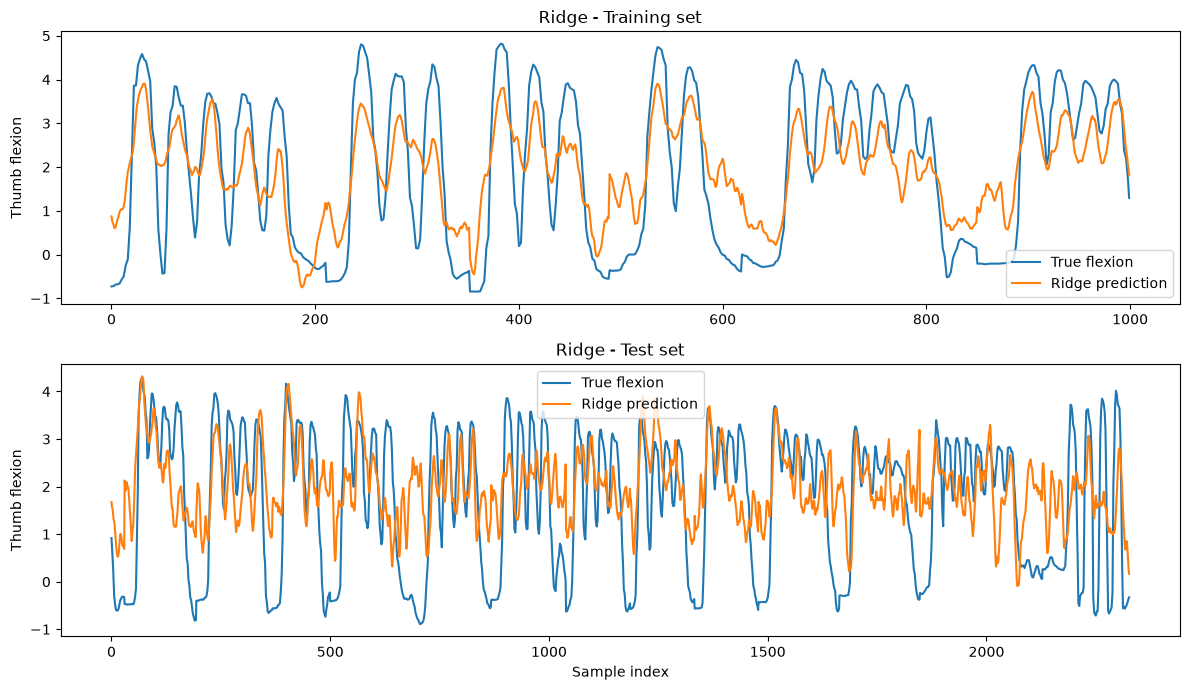

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(y_train, label="True flexion")
axes[0].plot(y_ridge_train, label="Ridge prediction")
axes[0].set_title("Ridge - Training set")
axes[0].set_ylabel("Thumb flexion")
axes[0].legend()

axes[1].plot(y_test, label="True flexion")
axes[1].plot(y_ridge_test, label="Ridge prediction")
axes[1].set_title("Ridge - Test set")
axes[1].set_xlabel("Sample index")
axes[1].set_ylabel("Thumb flexion")
axes[1].legend()

plt.tight_layout()
plt.show()

Ridge captures the general pattern of finger movement, especially on the training set.

However, it tends to underestimate high flexion values and overestimate low ones.

On the test set, the predictions are less accurate, but they are more stable than with Least Squares.

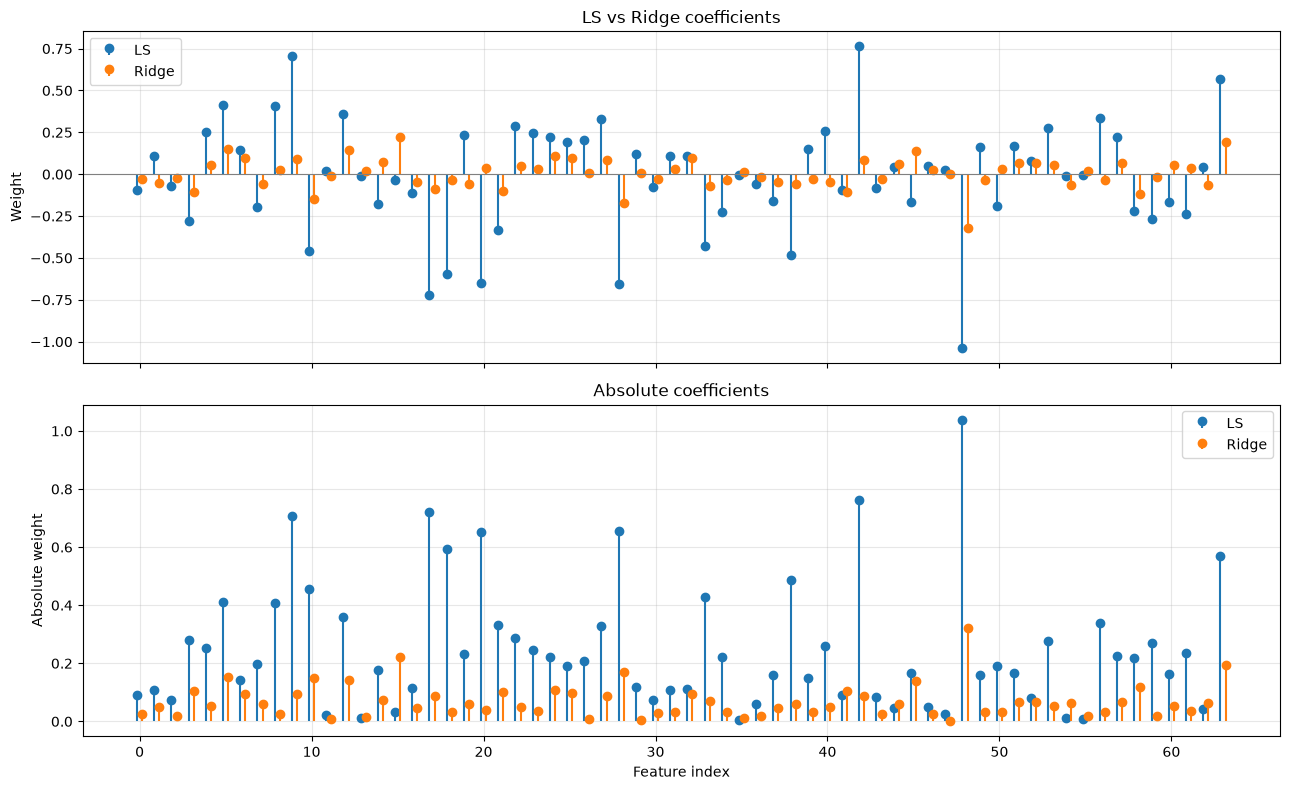

In [ ]:
w_ls = w
w_ridge = ridge_best.coef_

features = np.arange(64)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Signed coefficients
axes[0].stem(features - 0.15, w_ls, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="LS")
axes[0].stem(features + 0.15, w_ridge, linefmt="C1-", markerfmt="C1o", basefmt=" ", label="Ridge")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_ylabel("Weight")
axes[0].set_title("LS vs Ridge coefficients")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Absolute coefficients
axes[1].stem(features - 0.15, np.abs(w_ls), linefmt="C0-", markerfmt="C0o", basefmt=" ", label="LS")
axes[1].stem(features + 0.15, np.abs(w_ridge), linefmt="C1-", markerfmt="C1o", basefmt=" ", label="Ridge")
axes[1].set_xlabel("Feature index")
axes[1].set_ylabel("Absolute weight")
axes[1].set_title("Absolute coefficients")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Ridge produces much smaller coefficients than Least Squares, reducing the influence of individual features.

Feature 48 remains the most important in both models, but the relative importance of other features changes.

This suggests that Ridge distributes the weights differently while reducing their magnitude.

## Variable selection with the Lasso

In [ ]:
lasso = Lasso()
lasso.fit(X_train, y_train)

y_lasso_train = lasso.predict(X_train)
y_lasso_test = lasso.predict(X_test)

print("Lasso - default alpha = 1")
print(f"Train MSE: {mean_squared_error(y_train, y_lasso_train):.4f}")
print(f"Test MSE:  {mean_squared_error(y_test, y_lasso_test):.4f}")
print(f"Train R2:  {r2_score(y_train, y_lasso_train):.4f}")
print(f"Test R2:   {r2_score(y_test, y_lasso_test):.4f}")

print("\nWeights:", lasso.coef_)
print("Selected features:", np.count_nonzero(lasso.coef_))
print("Intercept:", lasso.intercept_)

Lasso - default alpha = 1
Train MSE: 3.1406
Test MSE:  2.1907
Train R2:  0.0000
Test R2:   -0.0273

Weights: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Selected features: 0
Intercept: 1.9443274007140745


With the default alpha = 1, Lasso sets all 64 coefficients to zero and only predicts the mean training value.

This leads to an R² of 0 on the training set and a slightly negative R² on the test set.

The model is clearly over-regularized and underfits the data.

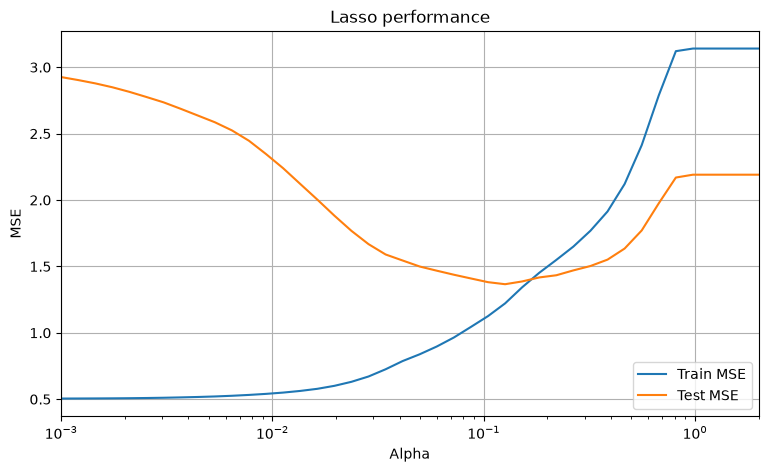

In [ ]:
alphas_lasso = np.logspace(-3, 5, 100)

mse_train_lasso = []
mse_test_lasso = []
weights_lasso = []

for alpha in alphas_lasso:
    model = Lasso(alpha=alpha)
    model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    mse_train_lasso.append(mean_squared_error(y_train, pred_train))
    mse_test_lasso.append(mean_squared_error(y_test, pred_test))

    weights_lasso.append(model.coef_)

weights_lasso = np.array(weights_lasso)

plt.figure(figsize=(9, 5))
plt.semilogx(alphas_lasso, mse_train_lasso, label="Train MSE")
plt.semilogx(alphas_lasso, mse_test_lasso, label="Test MSE")

plt.xlabel("Alpha")
plt.ylabel("MSE")
plt.title("Lasso performance")
plt.xlim(1e-3, 2)
plt.legend()
plt.grid(True)
plt.show()

As alpha increases, the test MSE first decreases and then increases, while the training MSE keeps increasing.

The best performance is reached around alpha = 0.1.

For large alpha values, both errors become constant because Lasso removes all features and only predicts the training mean.

In [ ]:
best_idx_lasso = np.argmin(mse_test_lasso)
best_alpha_lasso = alphas_lasso[best_idx_lasso]

lasso_best = Lasso(alpha=best_alpha_lasso)
lasso_best.fit(X_train, y_train)

y_lasso_train = lasso_best.predict(X_train)
y_lasso_test = lasso_best.predict(X_test)

print(f"Best alpha: {best_alpha_lasso:.4f}")
print(f"Train MSE: {mean_squared_error(y_train, y_lasso_train):.4f}")
print(f"Test MSE: {mean_squared_error(y_test, y_lasso_test):.4f}")
print(f"Train R2: {r2_score(y_train, y_lasso_train):.4f}")
print(f"Test R2: {r2_score(y_test, y_lasso_test):.4f}")

print(f"Selected features: {np.count_nonzero(lasso_best.coef_)} / 64")

Best alpha: 0.1262
Train MSE: 1.2216
Test MSE: 1.3660
Train R2: 0.6110
Test R2: 0.3595
Selected features: 14 / 64


The best Lasso model uses alpha = 0.1262 and achieves better test performance than Ridge, with a lower MSE and higher R².

It also selects only 14 out of 64 features, making the model simpler while improving generalization.

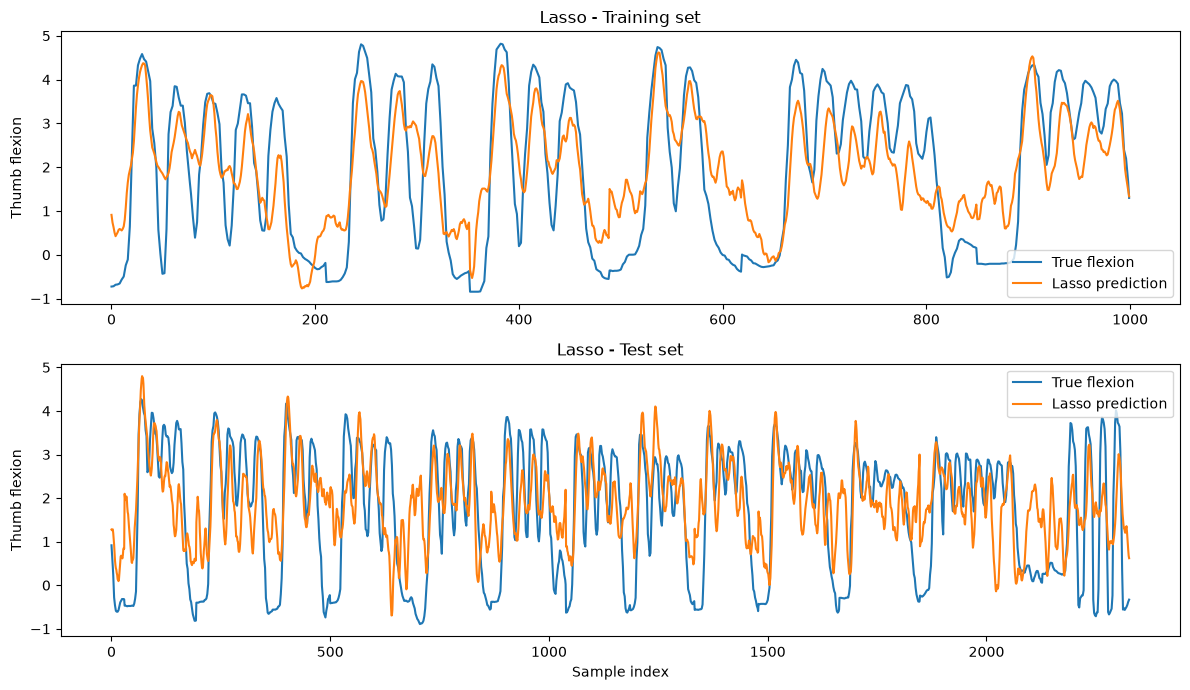

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].plot(y_train, label="True flexion")
axes[0].plot(y_lasso_train, label="Lasso prediction")
axes[0].set_title("Lasso - Training set")
axes[0].set_ylabel("Thumb flexion")
axes[0].legend()

axes[1].plot(y_test, label="True flexion")
axes[1].plot(y_lasso_test, label="Lasso prediction")
axes[1].set_title("Lasso - Test set")
axes[1].set_xlabel("Sample index")
axes[1].set_ylabel("Thumb flexion")
axes[1].legend()

plt.tight_layout()
plt.show()

Lasso follows the general pattern of finger movement on both datasets, but it still misses some peaks and overestimates low flexion values.

The predictions are not perfect, but the model achieves reasonable results using only 14 out of 64 features.

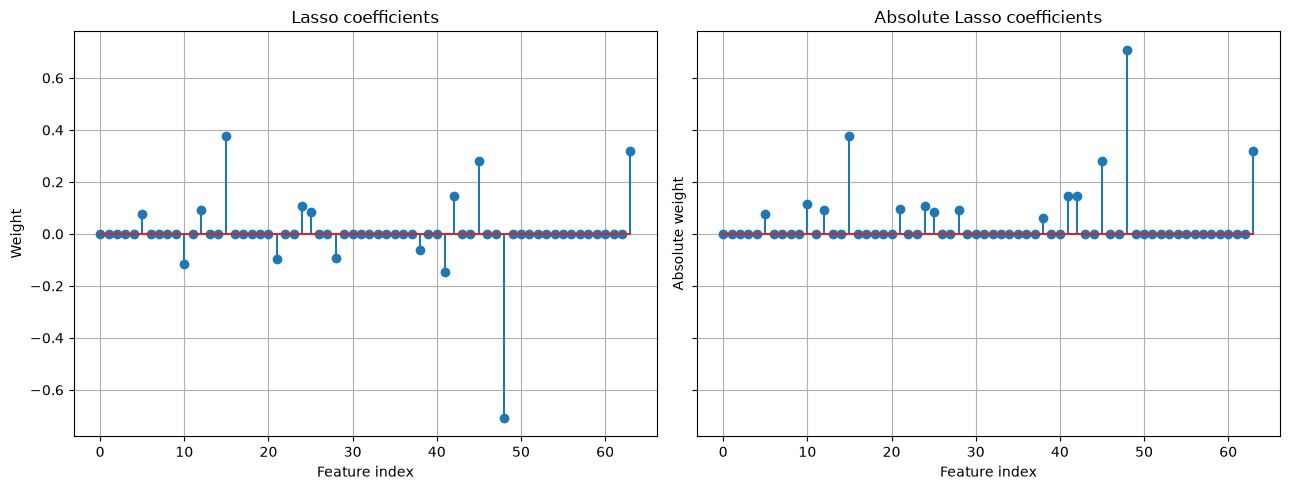

Two most important feature indices: [48 15]
Their coefficients: [-0.70862161  0.37611771]
Selected features: 14/64
Feature reduction: 78.1%


In [ ]:
w_lasso = lasso_best.coef_
features = np.arange(64)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

axes[0].stem(features, w_lasso)
axes[0].set_title("Lasso coefficients")
axes[0].set_xlabel("Feature index")
axes[0].set_ylabel("Weight")
axes[0].grid(True)

axes[1].stem(features, np.abs(w_lasso))
axes[1].set_title("Absolute Lasso coefficients")
axes[1].set_xlabel("Feature index")
axes[1].set_ylabel("Absolute weight")
axes[1].grid(True)

plt.tight_layout()
plt.show()

top_features = np.argsort(np.abs(w_lasso))[-2:][::-1]

print("Two most important feature indices:", top_features)
print("Their coefficients:", w_lasso[top_features])

n_selected = np.count_nonzero(w_lasso)
reduction = (1 - n_selected / 64) * 100

print(f"Selected features: {n_selected}/64")
print(f"Feature reduction: {reduction:.1f}%")

Lasso selects only 14 out of 64 features, reducing the number of variables by 78.1%.

Features 48 and 15 have the largest absolute coefficients, with feature 48 also being important in LS and Ridge.

This suggests that we could use fewer electrodes while keeping useful predictive performance.

## Nonlinear classification

In [ ]:
# Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

y_rf_train = rf.predict(X_train)
y_rf_test = rf.predict(X_test)

print("Random Forest - Default parameters")
print(f"Train MSE: {mean_squared_error(y_train, y_rf_train):.4f}")
print(f"Test MSE:  {mean_squared_error(y_test, y_rf_test):.4f}")
print(f"Train R2:  {r2_score(y_train, y_rf_train):.4f}")
print(f"Test R2:   {r2_score(y_test, y_rf_test):.4f}")

Random Forest - Default parameters
Train MSE: 0.0223
Test MSE:  1.6257
Train R2:  0.9929
Test R2:   0.2377


Random Forest fits the training data extremely well, with an R² close to 1.

However, its test performance is much worse and remains below Lasso.

This suggests strong overfitting, as the model learns the training data very well but struggles to generalize.

In [ ]:
# SVR
svr = SVR()
svr.fit(X_train, y_train)

y_svr_train = svr.predict(X_train)
y_svr_test = svr.predict(X_test)

print("SVR - Default parameters")
print(f"Train MSE: {mean_squared_error(y_train, y_svr_train):.4f}")
print(f"Test MSE:  {mean_squared_error(y_test, y_svr_test):.4f}")
print(f"Train R2:  {r2_score(y_train, y_svr_train):.4f}")
print(f"Test R2:   {r2_score(y_test, y_svr_test):.4f}")

SVR - Default parameters
Train MSE: 0.0241
Test MSE:  1.5152
Train R2:  0.9923
Test R2:   0.2895


SVR performs very well on the training set but much worse on the test set, suggesting overfitting.

It generalizes slightly better than Random Forest, but its test performance is still below Lasso.

In [ ]:
# MLP
mlp = MLPRegressor(random_state=42)
mlp.fit(X_train, y_train)

y_mlp_train = mlp.predict(X_train)
y_mlp_test = mlp.predict(X_test)

print("MLP - Default parameters")
print(f"Train MSE: {mean_squared_error(y_train, y_mlp_train):.4f}")
print(f"Test MSE:  {mean_squared_error(y_test, y_mlp_test):.4f}")
print(f"Train R2:  {r2_score(y_train, y_mlp_train):.4f}")
print(f"Test R2:   {r2_score(y_test, y_mlp_test):.4f}")

MLP - Default parameters
Train MSE: 0.0092
Test MSE:  2.5374
Train R2:  0.9971
Test R2:   -0.1899


MLP achieves almost perfect performance on the training set, but its test R² is negative.

This suggests severe overfitting, as the network fits the training data very well but fails to generalize.

It also performs worse than Random Forest and SVR on the test set.

In [ ]:
# Gradient Boosting
gb = GradientBoostingRegressor(random_state=42)
gb.fit(X_train, y_train)

y_gb_train = gb.predict(X_train)
y_gb_test = gb.predict(X_test)

print("Gradient Boosting - Default parameters")
print(f"Train MSE: {mean_squared_error(y_train, y_gb_train):.4f}")
print(f"Test MSE:  {mean_squared_error(y_test, y_gb_test):.4f}")
print(f"Train R2:  {r2_score(y_train, y_gb_train):.4f}")
print(f"Test R2:   {r2_score(y_test, y_gb_test):.4f}")

Gradient Boosting - Default parameters
Train MSE: 0.1133
Test MSE:  1.6743
Train R2:  0.9639
Test R2:   0.2149


Gradient Boosting fits the training data well but performs much worse on the test set, suggesting overfitting.

Its test performance is slightly worse than Random Forest and SVR. So far, Lasso still gives the best test results.

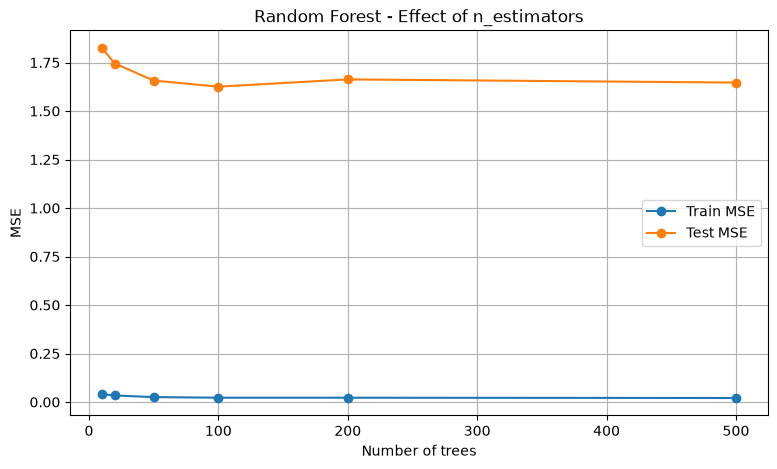

Best n_estimators: 100
Best test MSE: 1.6257


In [ ]:
# Random Forest important parameters to adjust: n_estimators, max_features
n_estimators_values = [10, 20, 50, 100, 200, 500]

rf_n_train_mse = []
rf_n_test_mse = []

for n_trees in n_estimators_values:
    model = RandomForestRegressor(n_estimators=n_trees, random_state=42)

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    rf_n_train_mse.append(mean_squared_error(y_train, train_pred))
    rf_n_test_mse.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(9, 5))

plt.plot(n_estimators_values, rf_n_train_mse, "o-", label="Train MSE")
plt.plot(n_estimators_values, rf_n_test_mse, "o-", label="Test MSE")

plt.xlabel("Number of trees")
plt.ylabel("MSE")
plt.title("Random Forest - Effect of n_estimators")
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(rf_n_test_mse)

print("Best n_estimators:", n_estimators_values[best_idx])
print(f"Best test MSE: {rf_n_test_mse[best_idx]:.4f}")

Increasing the number of trees improves test performance at first, but the improvement stops around 100 trees.

Adding more trees does not significantly improve generalization, while increasing computational cost.

Therefore, 100 trees seems to be a reasonable choice.

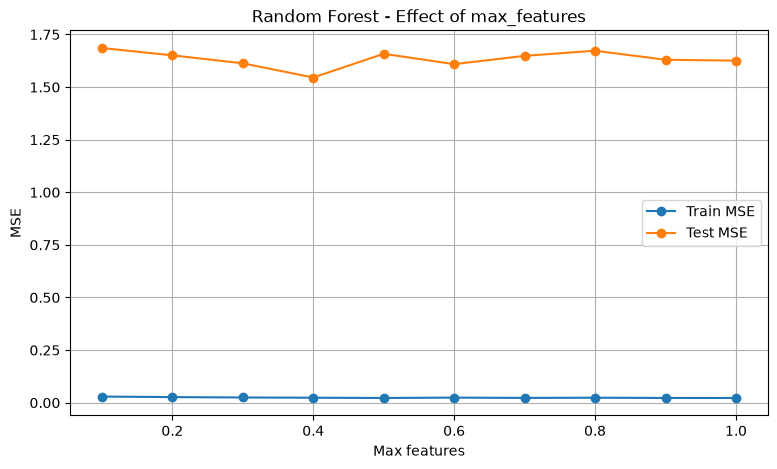

Best max_features: 0.4
Best test MSE: 1.5455


In [ ]:
# Random Forest important parameters to adjust: n_estimators, max_features
max_features_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

rf_feature_train_mse = []
rf_feature_test_mse = []

for max_features in max_features_values:
    model = RandomForestRegressor(max_features=max_features, random_state=42)

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    rf_feature_train_mse.append(mean_squared_error(y_train, train_pred))
    rf_feature_test_mse.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(9, 5))

plt.plot(max_features_values, rf_feature_train_mse, "o-", label="Train MSE")
plt.plot(max_features_values, rf_feature_test_mse, "o-", label="Test MSE")

plt.xlabel("Max features")
plt.ylabel("MSE")
plt.title("Random Forest - Effect of max_features")
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(rf_feature_test_mse)

print("Best max_features:", max_features_values[best_idx])
print(f"Best test MSE: {rf_feature_test_mse[best_idx]:.4f}")

Reducing max_features improves test performance slightly, with the best result at 0.4.

This suggests that introducing more randomness between trees helps generalization.

However, the large gap between training and test errors remains.

In [ ]:
rf_best = RandomForestRegressor(n_estimators=100, max_features=0.4, random_state=42)

rf_best.fit(X_train, y_train)

y_rf_best_train = rf_best.predict(X_train)
y_rf_best_test = rf_best.predict(X_test)

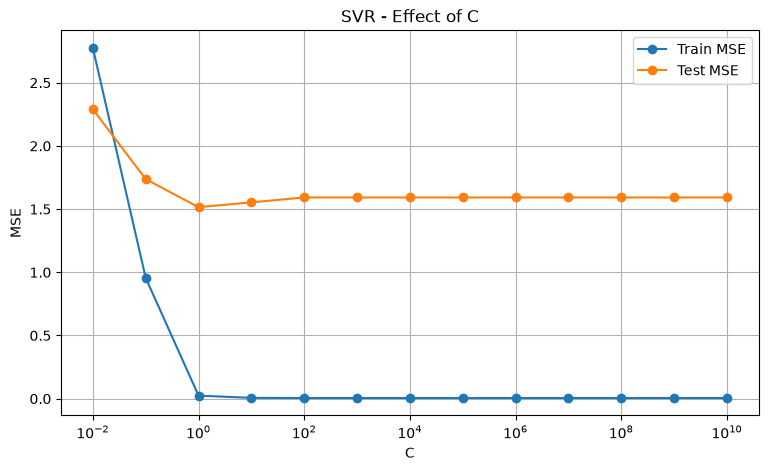

Best C: 1.0
Best test MSE: 1.5152


In [ ]:
# SVR RBF kernel important parameters : C, gamma
C_values = np.logspace(-2, 10, 13)

svr_train_mse = []
svr_test_mse = []

for C in C_values:
    model = SVR(C=C)

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    svr_train_mse.append(mean_squared_error(y_train, train_pred))
    svr_test_mse.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(9, 5))

plt.semilogx(C_values, svr_train_mse, "o-", label="Train MSE")
plt.semilogx(C_values, svr_test_mse, "o-", label="Test MSE")

plt.xlabel("C")
plt.ylabel("MSE")
plt.title("SVR - Effect of C")
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(svr_test_mse)
best_C = C_values[best_idx]

print("Best C:", best_C)
print(f"Best test MSE: {svr_test_mse[best_idx]:.4f}")

Increasing C improves performance at first, with the best test MSE obtained at C = 1.

For larger values, the training error becomes almost zero, but the test error increases slightly.

This suggests overfitting when regularization is too weak.

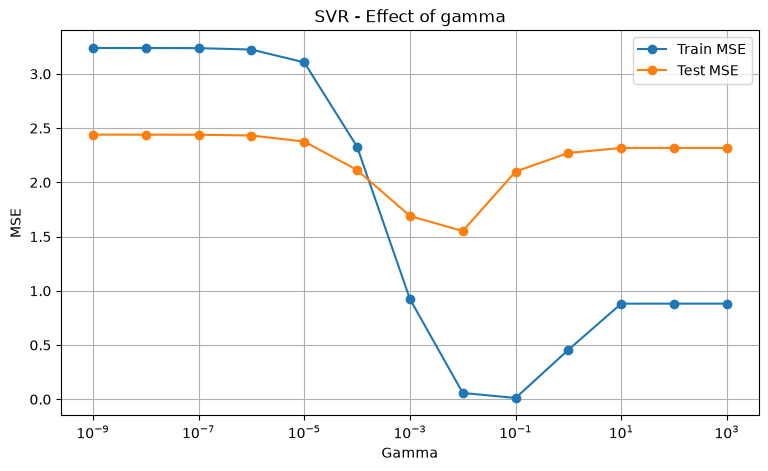

Default gamma: 0.015433
Best gamma: 0.010000
Best test MSE: 1.5512


In [ ]:
# SVR RBF kernel important parameters : C, gamma
gamma_values = np.logspace(-9, 3, 13)

svr_gamma_train_mse = []
svr_gamma_test_mse = []

for gamma in gamma_values:
    model = SVR(gamma=gamma)
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    svr_gamma_train_mse.append(mean_squared_error(y_train, train_pred))
    svr_gamma_test_mse.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(9, 5))
plt.semilogx(gamma_values, svr_gamma_train_mse, "o-", label="Train MSE")
plt.semilogx(gamma_values, svr_gamma_test_mse, "o-", label="Test MSE")

plt.xlabel("Gamma")
plt.ylabel("MSE")
plt.title("SVR - Effect of gamma")
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(svr_gamma_test_mse)
best_gamma = gamma_values[best_idx]

gamma_default = 1 / (X_train.shape[1] * X_train.var())
print(f"Default gamma: {gamma_default:.6f}")
print(f"Best gamma: {best_gamma:.6f}")
print(f"Best test MSE: {svr_gamma_test_mse[best_idx]:.4f}")

SVR performance is strongly affected by gamma.

Small gamma values lead to underfitting, while large values make the model too sensitive to individual samples.

The best tested gamma is 0.01, but the default setting still gives slightly better test performance.

In [ ]:
svr_best = SVR(C=1, gamma="scale")
svr_best.fit(X_train, y_train)

y_svr_best_train = svr_best.predict(X_train)
y_svr_best_test = svr_best.predict(X_test)

Hidden neurons: 5, Epochs: 555
Hidden neurons: 10, Epochs: 438
Hidden neurons: 20, Epochs: 233
Hidden neurons: 50, Epochs: 182
Hidden neurons: 100, Epochs: 140
Hidden neurons: 200, Epochs: 124


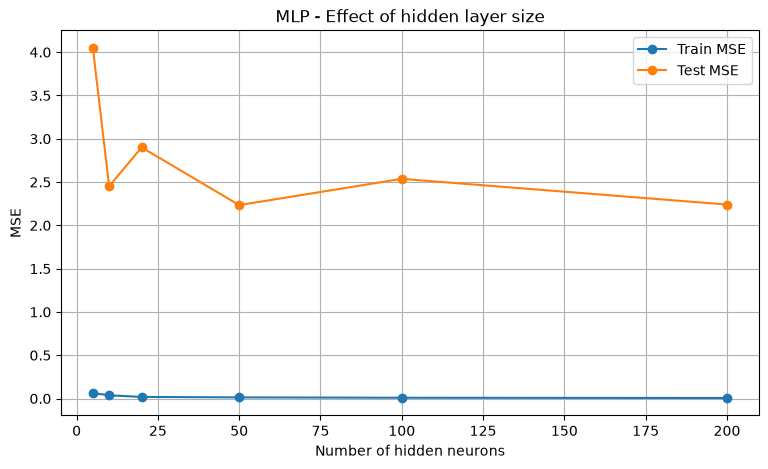

Best hidden layer size: 50
Best test MSE: 2.2339


In [ ]:
# MLP important parameters : hidden_layer_sizes, alpha
hidden_sizes = [5, 10, 20, 50, 100, 200]

mlp_train_mse = []
mlp_test_mse = []

for size in hidden_sizes:
    model = MLPRegressor(hidden_layer_sizes=(size,), max_iter=1000, random_state=42)

    model.fit(X_train, y_train)
    print(f"Hidden neurons: {size}, Epochs: {model.n_iter_}")

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    mlp_train_mse.append(mean_squared_error(y_train, train_pred))
    mlp_test_mse.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(9, 5))

plt.plot(hidden_sizes, mlp_train_mse, "o-", label="Train MSE")
plt.plot(hidden_sizes, mlp_test_mse, "o-", label="Test MSE")

plt.xlabel("Number of hidden neurons")
plt.ylabel("MSE")
plt.title("MLP - Effect of hidden layer size")
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(mlp_test_mse)

print("Best hidden layer size:", hidden_sizes[best_idx])
print(f"Best test MSE: {mlp_test_mse[best_idx]:.4f}")

The MLP performs poorly with only 5 neurons.

Increasing the number of neurons improves training performance, but the test error remains high.

The best result is obtained with 50 neurons, although the model still shows significant overfitting.

alpha: 0.0001, Epochs: 140
alpha: 0.00031622776601683794, Epochs: 140
alpha: 0.001, Epochs: 140
alpha: 0.0031622776601683794, Epochs: 140
alpha: 0.01, Epochs: 140
alpha: 0.03162277660168379, Epochs: 140
alpha: 0.1, Epochs: 169
alpha: 0.31622776601683794, Epochs: 466
alpha: 1.0, Epochs: 494
alpha: 3.1622776601683795, Epochs: 360
alpha: 10.0, Epochs: 316
alpha: 31.622776601683793, Epochs: 275
alpha: 100.0, Epochs: 225
alpha: 316.22776601683796, Epochs: 220
alpha: 1000.0, Epochs: 761
alpha: 3162.2776601683795, Epochs: 853
alpha: 10000.0, Epochs: 775
alpha: 31622.776601683792, Epochs: 721
alpha: 100000.0, Epochs: 671
alpha: 316227.7660168379, Epochs: 650
alpha: 1000000.0, Epochs: 665


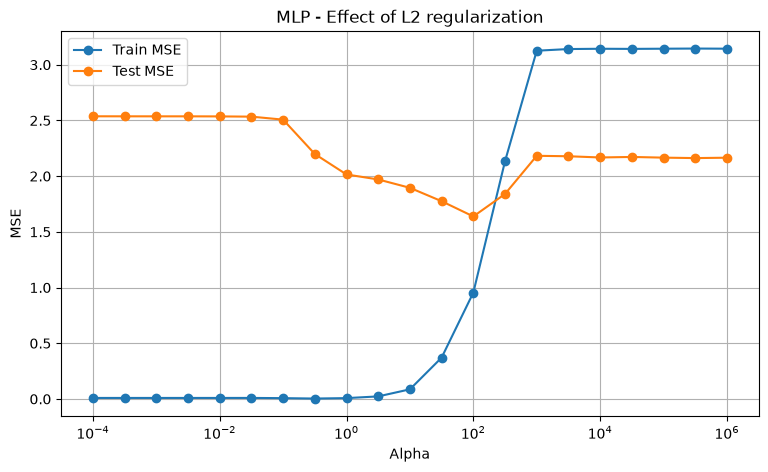

Best alpha: 100.0
Best test MSE: 1.6383


In [ ]:
# MLP important parameters : hidden_layer_sizes, alpha
alpha_values = np.logspace(-4, 6, 21)

mlp_alpha_train_mse = []
mlp_alpha_test_mse = []

for alpha in alpha_values:
    model = MLPRegressor(alpha=alpha, max_iter=1000, random_state=42)

    model.fit(X_train, y_train)
    print(f"alpha: {alpha}, Epochs: {model.n_iter_}")

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    mlp_alpha_train_mse.append(mean_squared_error(y_train, train_pred))
    mlp_alpha_test_mse.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(9, 5))

plt.semilogx(alpha_values, mlp_alpha_train_mse, "o-", label="Train MSE")
plt.semilogx(alpha_values, mlp_alpha_test_mse, "o-", label="Test MSE")

plt.xlabel("Alpha")
plt.ylabel("MSE")
plt.title("MLP - Effect of L2 regularization")
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(mlp_alpha_test_mse)
best_alpha_mlp = alpha_values[best_idx]

print("Best alpha:", best_alpha_mlp)
print(f"Best test MSE: {mlp_alpha_test_mse[best_idx]:.4f}")

Increasing alpha initially improves test performance by reducing overfitting.

The best result is obtained at alpha = 100.

Beyond this value, both errors increase and eventually stabilize, showing that too much regularization leads to underfitting.

In [ ]:
mlp_best = MLPRegressor(hidden_layer_sizes=(50,), alpha=100, max_iter=1000, random_state=42)
mlp_best.fit(X_train, y_train)

y_mlp_best_train = mlp_best.predict(X_train)
y_mlp_best_test = mlp_best.predict(X_test)

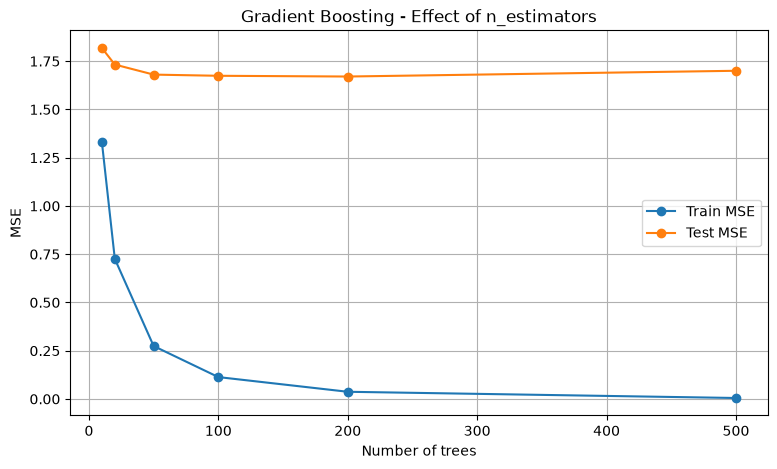

Best n_estimators: 200
Best test MSE: 1.6704


In [ ]:
# GradientBoosting important parameters : n_estimators, learning_rate
n_estimators_values = [10, 20, 50, 100, 200, 500]

gb_train_mse = []
gb_test_mse = []

for n_trees in n_estimators_values:
    model = GradientBoostingRegressor(n_estimators=n_trees, random_state=42)

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    gb_train_mse.append(mean_squared_error(y_train, train_pred))
    gb_test_mse.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(9, 5))

plt.plot(n_estimators_values, gb_train_mse, "o-", label="Train MSE")
plt.plot(n_estimators_values, gb_test_mse, "o-", label="Test MSE")

plt.xlabel("Number of trees")
plt.ylabel("MSE")
plt.title("Gradient Boosting - Effect of n_estimators")
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(gb_test_mse)
best_n_estimators_gb = n_estimators_values[best_idx]

print("Best n_estimators:", best_n_estimators_gb)
print(f"Best test MSE: {gb_test_mse[best_idx]:.4f}")

Increasing the number of trees greatly reduces the training error, but only slightly improves the test performance.

The best result is obtained with 200 trees, although the improvement is very small.

Adding more trees mainly increases overfitting.

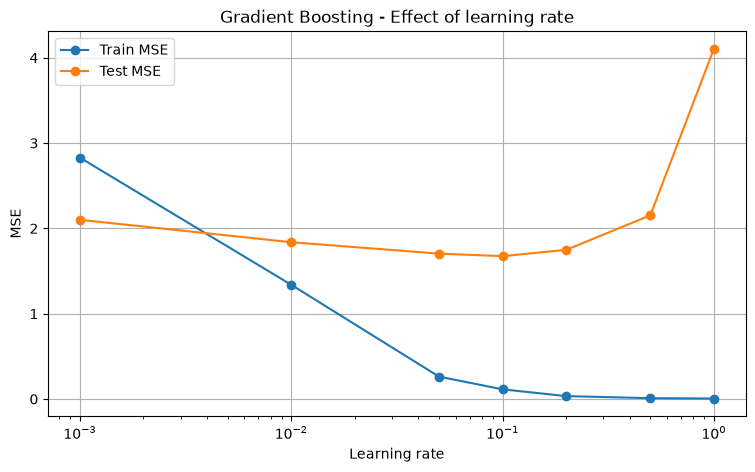

Best learning rate: 0.1
Best test MSE: 1.6743


In [ ]:
# GradientBoosting important parameters : n_estimators, learning_rate
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0]

gb_lr_train_mse = []
gb_lr_test_mse = []

for lr in learning_rates:
    model = GradientBoostingRegressor(learning_rate=lr, random_state=42)

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    gb_lr_train_mse.append(mean_squared_error(y_train, train_pred))
    gb_lr_test_mse.append(mean_squared_error(y_test, test_pred))

plt.figure(figsize=(9, 5))

plt.semilogx(learning_rates, gb_lr_train_mse, "o-", label="Train MSE")
plt.semilogx(learning_rates, gb_lr_test_mse, "o-", label="Test MSE")

plt.xlabel("Learning rate")
plt.ylabel("MSE")
plt.title("Gradient Boosting - Effect of learning rate")
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmin(gb_lr_test_mse)
best_learning_rate_gb = learning_rates[best_idx]

print("Best learning rate:", best_learning_rate_gb)
print(f"Best test MSE: {gb_lr_test_mse[best_idx]:.4f}")

The learning rate strongly affects Gradient Boosting performance.

Small values lead to underfitting, while large values increase overfitting.

The best result is obtained around 0.1, giving a good balance between training and test performance.

In [ ]:
gb_best = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, random_state=42)
gb_best.fit(X_train, y_train)

y_gb_best_train = gb_best.predict(X_train)
y_gb_best_test = gb_best.predict(X_test)

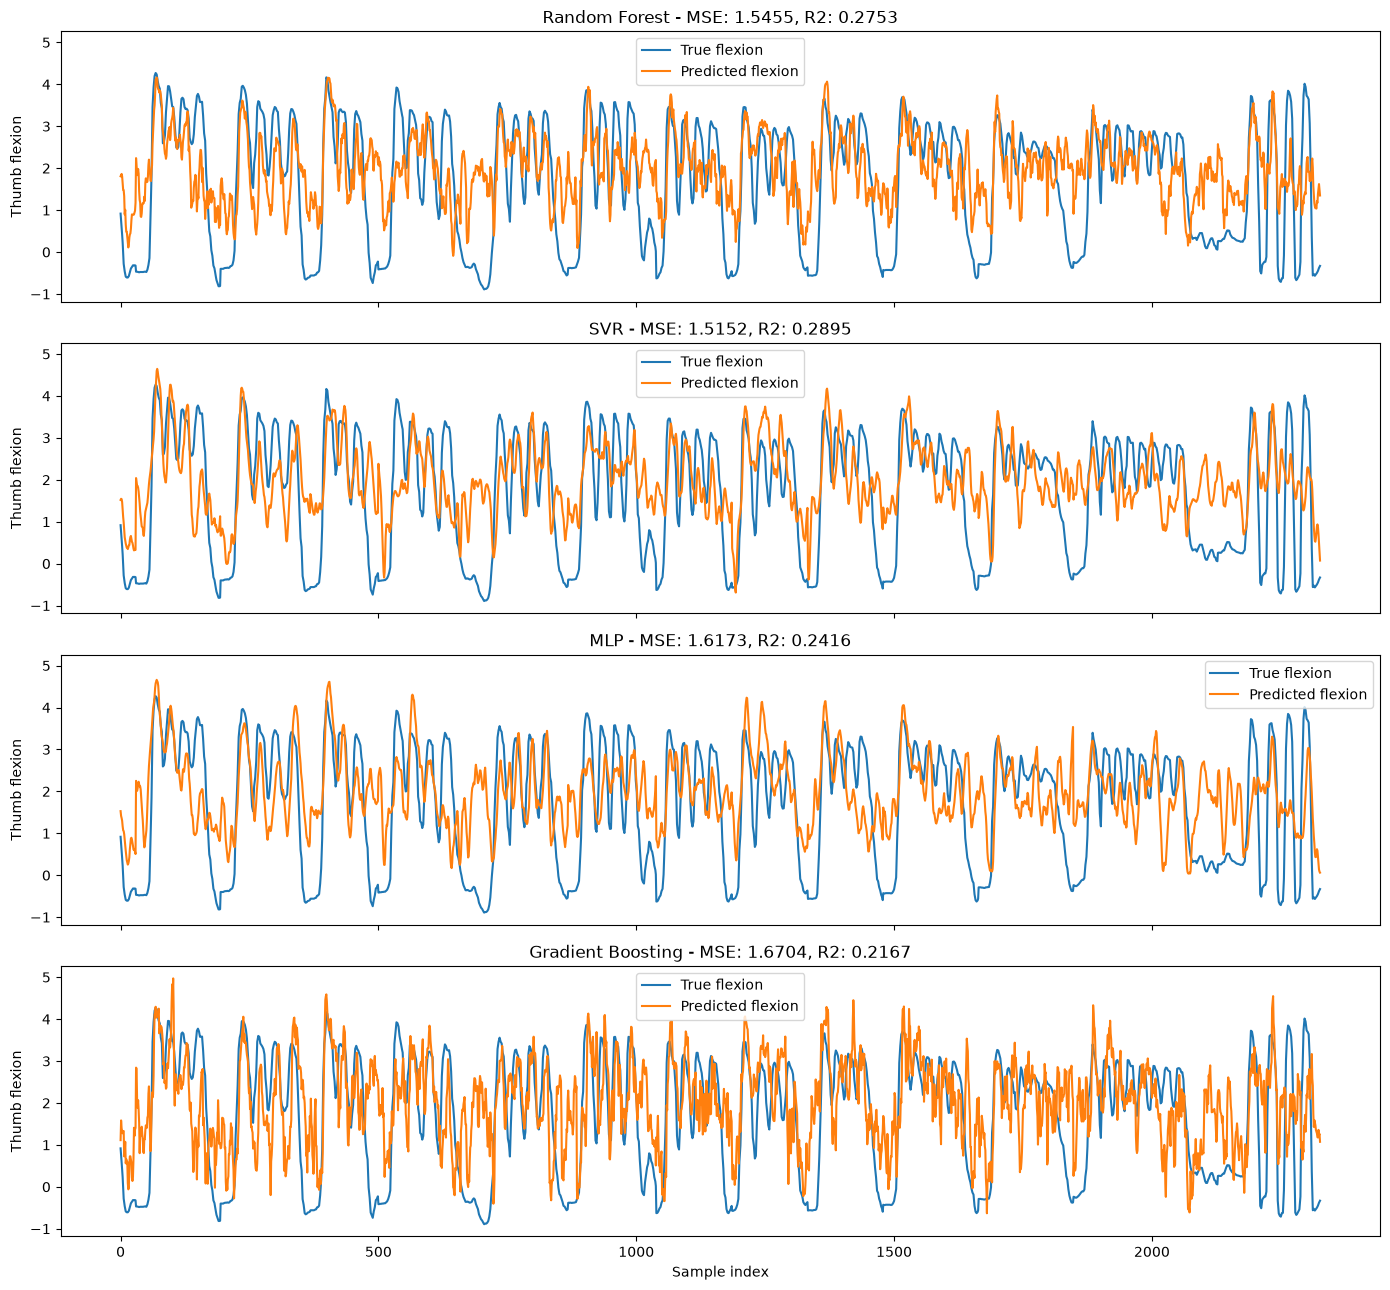

In [ ]:
# Visualization
predictions = {
    "Random Forest": y_rf_best_test,
    "SVR": y_svr_best_test,
    "MLP": y_mlp_best_test,
    "Gradient Boosting": y_gb_best_test
}

fig, axes = plt.subplots(4, 1, figsize=(14, 13), sharex=True, sharey=True)

for ax, (name, y_pred) in zip(axes, predictions.items()):

    ax.plot(y_test, label="True flexion")
    ax.plot(y_pred, label="Predicted flexion")

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    ax.set_title(f"{name} - MSE: {mse:.4f}, R2: {r2:.4f}")
    ax.set_ylabel("Thumb flexion")
    ax.legend()

axes[-1].set_xlabel("Sample index")

plt.tight_layout()
plt.show()

**Random Forest:** The model captures some finger movements but tends to overestimate low flexion values and misses several peaks. Its predictions remain quite inaccurate.

**SVR:** SVR follows the finger movements slightly better than the other nonlinear models. However, it still struggles to predict low flexion values accurately.

**MLP:** The regularized MLP captures the general movement pattern, but its predictions remain inaccurate, especially during low flexion periods.

**Gradient Boosting:** The predictions are quite noisy and often miss the true flexion values. It has the highest test MSE among the four optimized nonlinear models.

## Final comparison of the performances

In [ ]:
# Collect predictions from all models
results = {
    "Least Squares": (y_pred_train, y_pred_test),
    "Ridge": (y_ridge_train, y_ridge_test),
    "Lasso": (y_lasso_train, y_lasso_test),
    "Random Forest": (y_rf_best_train, y_rf_best_test),
    "SVR": (y_svr_best_train, y_svr_best_test),
    "MLP": (y_mlp_best_train, y_mlp_best_test),
    "Gradient Boosting": (y_gb_best_train, y_gb_best_test)
}

# Compute performance metrics
comparison = []

for name, (train_pred, test_pred) in results.items():
    comparison.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    })

# Create and sort the comparison table
df_results = pd.DataFrame(comparison)
df_results = df_results.sort_values("Test MSE")

print(df_results.round(4).to_string(index=False))

            Model  Train MSE  Test MSE  Train R2  Test R2
            Lasso     1.2216    1.3660    0.6110   0.3595
              SVR     0.0241    1.5152    0.9923   0.2895
    Random Forest     0.0236    1.5455    0.9925   0.2753
              MLP     0.9567    1.6173    0.6954   0.2416
            Ridge     1.1719    1.6239    0.6268   0.2385
Gradient Boosting     0.0372    1.6704    0.9881   0.2167
    Least Squares     0.5041    3.0455    0.8395  -0.4282


Lasso achieves the best test performance, with an MSE of 1.3660 and an R² of 0.3595. SVR and Random Forest come next. \
More complex models tend to fit the training data better but do not necessarily generalize better.

Linear models are the easiest to interpret because their coefficients show how each feature affects the prediction. \
Lasso is particularly interesting because it selects only 14 out of 64 features, making the model simpler.

Lasso seems to be the most promising choice. \
It gives the best test performance while using only 14 features, potentially reducing the number of electrodes needed. \
However, this would require further validation before any medical application.

Based on our results, non-linearity does not seem necessary. \
Lasso outperforms all the nonlinear models we tested. \
However, better nonlinear architectures or additional tuning might still improve performance.

No. \
Using the test set to select hyperparameters introduces data leakage and can lead to overly optimistic results. \
In practice, we should use a separate validation set or cross-validation for hyperparameter tuning, and keep the test set untouched for the final evaluation. \
Since our data is temporal, chronological validation would be more appropriate.

## Personal discussion

What I found most interesting in this practical session was seeing how regularization affects model coefficients and generalization. \
I also enjoyed exploring the impact of hyperparameters and comparing linear and nonlinear models. \
It was surprising to see that a simpler model like Lasso could outperform more complex models.

At first, I found it strange that we were tuning hyperparameters directly on the test set because of data leakage. \
I also had some difficulty understanding the usefulness of training performance when our main objective is generalization.

Overall, this session helped me better understand overfitting, regularization, model selection, and the importance of evaluating models on unseen data.

Next time, I would use a separate validation set for hyperparameter tuning and keep the test set for final evaluation.

In a real BCI application, I would also consider the trade-off between prediction accuracy, model complexity, and the number of electrodes required.